# Problem 1: Floating-point softmax and cross-entropy

## Group Members :

Lakshya Arukiya (240589) 

Priyanshu Verma (240811)

Arpit Kumar Singh (240194)

Chirag Gupta (240311)

Saurabh Raj (240947)

In [1]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import json
torch.manual_seed(0)
torch.set_num_threads(4)
print('PyTorch:', torch.__version__, '| device: CPU')
plt.rcParams.update({'figure.dpi':110, 'axes.grid':True, 'grid.alpha':0.25})

PyTorch: 2.8.0 | device: CPU


## Part I: Prediction and derivation
$F(1000,999)$ is finite, approximately $1000.3133$. Direct exponentiation should overflow in both formats.

For $c=\max(a,b)$,
$$\log(e^a+e^b)=\log[e^c(e^{a-c}+e^{b-c})]=c+\log(e^{a-c}+e^{b-c}).$$
Generally, $\log\sum_i e^{x_i}=c+\log\sum_i e^{x_i-c}$, where $c=\max_i x_i$. Factoring changes no real-arithmetic value. Every exponent is nonpositive, so its exponential is at most one; one term equals one. These claims assume finite inputs.

In [2]:
def own_lse(x):
    c = x.max()
    return c + torch.log(torch.exp(x-c).sum())
pairs = [(1.,2.), (1000.,999.), (-1000.,-1001.), (0.,-100.)]
for dtype in (torch.float32, torch.float64):
    for a,b in pairs:
        x=torch.tensor([a,b],dtype=dtype)
        naive=torch.log(torch.exp(x).sum())
        stable=own_lse(x)
        assert torch.isfinite(stable)
        print(dtype, (a,b), 'naive=',naive.item(),'ours=',stable.item())

torch.float32 (1.0, 2.0) naive= 2.3132617473602295 ours= 2.3132617473602295
torch.float32 (1000.0, 999.0) naive= inf ours= 1000.313232421875
torch.float32 (-1000.0, -1001.0) naive= -inf ours= -999.686767578125
torch.float32 (0.0, -100.0) naive= 0.0 ours= 0.0
torch.float64 (1.0, 2.0) naive= 2.3132616875182226 ours= 2.313261687518223
torch.float64 (1000.0, 999.0) naive= inf ours= 1000.3132616875182
torch.float64 (-1000.0, -1001.0) naive= -inf ours= -999.6867383124818
torch.float64 (0.0, -100.0) naive= 0.0 ours= 0.0


## Part II: Library primitives and the ML bridge
The primitives implement the same mathematics while avoiding exponential overflow and complete underflow. Very negative inputs make the naive sum zero and its logarithm negative infinity; shifting retains a representable sum. Small corrections can still round away.

For cross-entropy, $L=\log\sum_j e^{z_j}-z_y$. Stable log-sum-exp helps the forward computation, but whether related gradients remain stable is a separate question.

In [3]:
for dtype in (torch.float32, torch.float64):
    for a,b in pairs:
        x=torch.tensor([a,b],dtype=dtype)
        print(dtype,(a,b),'ours',own_lse(x).item(), 'logaddexp',torch.logaddexp(x[0],x[1]).item(),'logsumexp',torch.logsumexp(x,0).item())
        assert torch.allclose(own_lse(x),torch.logsumexp(x,0))

torch.float32 (1.0, 2.0) ours 2.3132617473602295 logaddexp 2.3132617473602295 logsumexp 2.3132617473602295
torch.float32 (1000.0, 999.0) ours 1000.313232421875 logaddexp 1000.313232421875 logsumexp 1000.313232421875
torch.float32 (-1000.0, -1001.0) ours -999.686767578125 logaddexp -999.686767578125 logsumexp -999.686767578125
torch.float32 (0.0, -100.0) ours 0.0 logaddexp 3.783505853677006e-44 logsumexp 0.0
torch.float64 (1.0, 2.0) ours 2.313261687518223 logaddexp 2.313261687518223 logsumexp 2.313261687518223
torch.float64 (1000.0, 999.0) ours 1000.3132616875182 logaddexp 1000.3132616875182 logsumexp 1000.3132616875182
torch.float64 (-1000.0, -1001.0) ours -999.6867383124818 logaddexp -999.6867383124818 logsumexp -999.6867383124818
torch.float64 (0.0, -100.0) ours 0.0 logaddexp 3.720075976020836e-44 logsumexp 0.0


## Part III: Prediction and invariant
$\sum_j g_j=\sum_j p_j-1=0$. At every finite margin, $g_0<0$ and $g_1>0$ in real arithmetic. I expect the target gradient to round to zero first, earlier in float32.

Computing $p_y-1$ loses relative accuracy near one and becomes zero when $p_y$ rounds to one. Max subtraction prevents overflow but does not restore those lost digits.

In [4]:
def library_gradient(m, dtype=torch.float32):
    z = torch.tensor([[m, 0., 0., 0., 0.]], dtype=dtype, requires_grad=True)
    loss = F.cross_entropy(z, torch.tensor([0]))
    loss.backward()
    return z.grad.detach()[0]
for m in (5.,10.,15.,20.,30.,40.):
    g=library_gradient(m)
    print(m,g[0].item(),g[1].item(),g.sum().item())
thresholds={}
for dtype in (torch.float32,torch.float64):
    hits=[m for m in np.arange(0,50.001,.05) if (lambda g:g[0]==0 and g[1]>0)(library_gradient(float(m),dtype))]
    thresholds[str(dtype)]=float(hits[0]) if hits else None
print('First collapse on 0.05 grid:', thresholds)

5.0 -0.02624446153640747 0.006561112590134144 -1.210719347000122e-08
10.0 -0.00018161535263061523 4.539170186035335e-05 -4.854518920183182e-08
15.0 -1.3113021850585938e-06 3.0590203436986485e-07 -8.769399073571549e-08
20.0 0.0 2.06115369216775e-09 8.244614768671e-09
30.0 0.0 9.357622912219837e-14 3.743049164887935e-13
40.0 0.0 4.24835413113866e-18 1.699341652455464e-17
First collapse on 0.05 grid: {'torch.float32': 17.35, 'torch.float64': 37.45}


## Part IV: A gradient without target cancellation
The non-target classes contribute $S=\sum_{j\ne y}e^{z_j}$ to the softmax denominator $D=e^{z_y}+S$. Their combined probability is $S/D$, so
$$g_y=-S/D=-\sum_{j\ne y}g_j,\qquad g_j=e^{z_j}/D\ (j\ne y).$$
With $c=\max_j z_j$, we compute $w_j=e^{z_j-c}$ and $g_j=w_j/\sum_i w_i$ for non-target classes. Their sum gives $-g_y$. No near-equal subtraction is needed. Underflow remains possible for tiny non-target probabilities.

In [5]:
def stable_grad(logits,y):
    if logits.ndim != 1 or not 0 <= y < logits.numel():
        raise ValueError('Expected one logit vector and a valid target')
    w=torch.exp(logits-logits.max())
    g=w/w.sum()
    keep=torch.arange(len(g),device=g.device)!=y
    g=g.clone()
    g[y]=-g[keep].sum()
    return g
cases=[([1.,2.,-1.],1),([0.,0.],1),([20.,0.,0.,0.,0.],0),([0.,80.,-10.],1),([1e4,-1e4,0.],2),([1000.,0.,-1000.],0)]
for dtype in (torch.float32,torch.float64):
    for values,y in cases:
        z=torch.tensor(values,dtype=dtype,requires_grad=True)
        F.cross_entropy(z[None],torch.tensor([y])).backward()
        g=stable_grad(z.detach(),y)
        assert g.shape==z.shape and torch.isfinite(g).all()
        assert g[y]<=0 and (g[torch.arange(len(g))!=y]>=0).all()
        assert abs(g.sum())<20*torch.finfo(dtype).eps
        if max(values)-min(values)<10: assert torch.allclose(g,z.grad,atol=1e-7,rtol=1e-5)
        print(dtype,values,'y=',y,'library=',z.grad.tolist(),'ours=',g.tolist(),'residual=',g.sum().item())
# Random moderate-logit tests cover multiple class counts and every label.
for k in (2,3,5,17):
    for y in range(k):
        z=torch.randn(k,dtype=torch.float64,requires_grad=True)
        F.cross_entropy(z[None],torch.tensor([y])).backward()
        assert torch.allclose(stable_grad(z.detach(),y),z.grad,atol=1e-14,rtol=1e-12)
print('All gradient checks passed')

torch.float32 [1.0, 2.0, -1.0] y= 1 library= [0.2594964802265167, -0.2946154475212097, 0.03511903062462807] ours= [0.2594964802265167, -0.2946155071258545, 0.03511902689933777] residual= 0.0
torch.float32 [0.0, 0.0] y= 1 library= [0.5, -0.5] ours= [0.5, -0.5] residual= 0.0
torch.float32 [20.0, 0.0, 0.0, 0.0, 0.0] y= 0 library= [0.0, 2.06115369216775e-09, 2.06115369216775e-09, 2.06115369216775e-09, 2.06115369216775e-09] ours= [-8.244614768671e-09, 2.06115369216775e-09, 2.06115369216775e-09, 2.06115369216775e-09, 2.06115369216775e-09] residual= 4.440892098500626e-16
torch.float32 [0.0, 80.0, -10.0] y= 1 library= [1.8048513285848406e-35, 0.0, 8.194008692231508e-40] ours= [1.8048513285848406e-35, -1.804933263066569e-35, 8.194008692231508e-40] residual= 5.605193857299268e-44
torch.float32 [10000.0, -10000.0, 0.0] y= 2 library= [1.0, 0.0, -1.0] ours= [1.0, 0.0, -1.0] residual= 0.0
torch.float32 [1000.0, 0.0, -1000.0] y= 0 library= [0.0, 0.0, 0.0] ours= [-0.0, 0.0, 0.0] residual= 0.0
torch.fl

## Part V: Evidence and reflection
The first collapse margins on the 0.05 grid were 17.35 (float32) and 37.45 (float64). Exact zeros are shown as crosses at a labelled display floor, not as positive measurements. The gradient agrees on moderate logits but retains the small negative target component after the library result collapses. Extreme differences eventually underflow even with the reformulation.

The naive calculation failed because exponentials exceeded the format's range; shifting changed intermediate magnitudes. Overflow is a range failure, whereas cancellation destroys significant digits when subtracting nearby values. A plausible loss does not certify its gradient: the high-confidence experiment exposes a zero target derivative alongside positive non-target derivatives. Summing non-target probabilities avoids target cancellation and improves the zero-sum invariant. It does not provide infinite precision, prevent all underflow, or guarantee exact zero residuals under arbitrary reduction order.

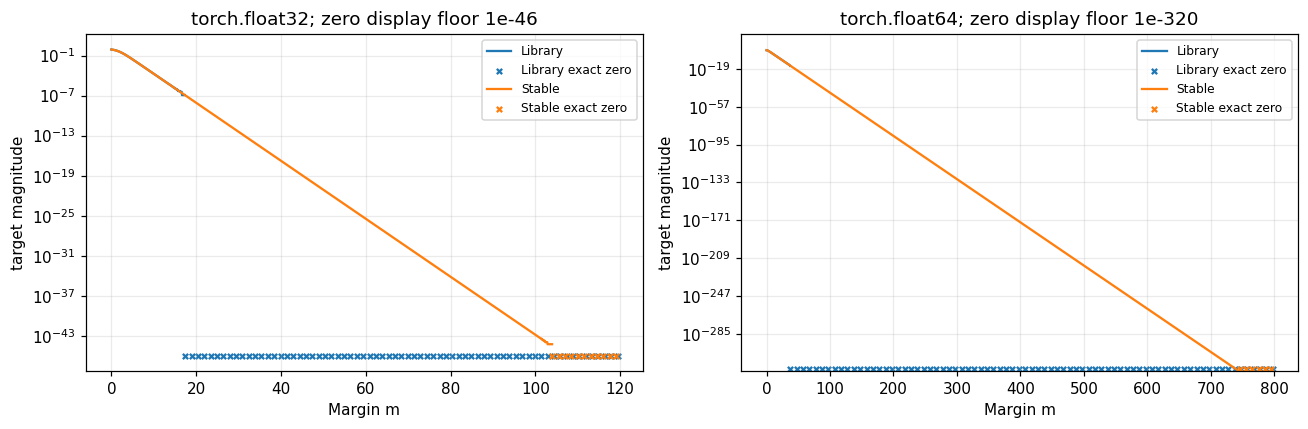

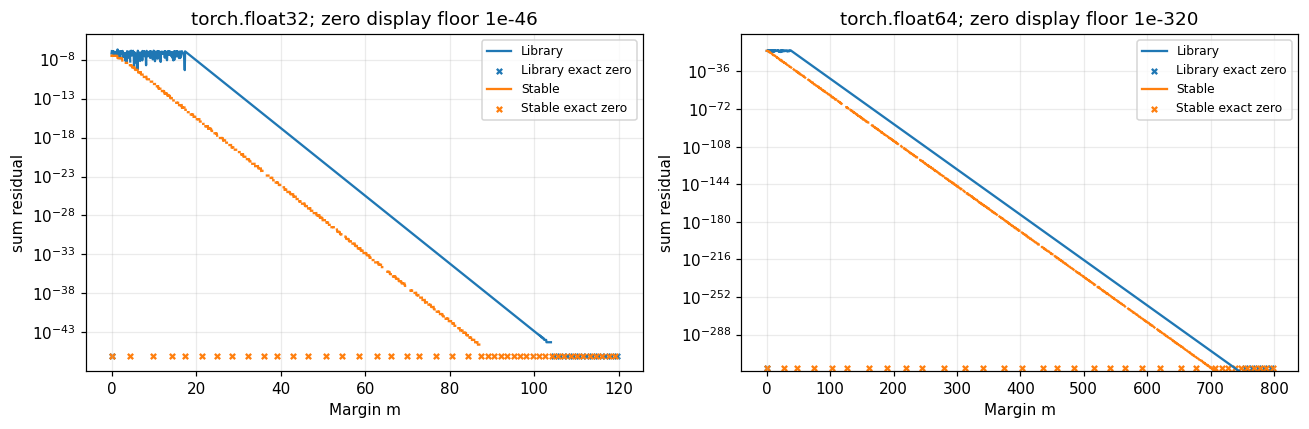

In [6]:
curves={}
for dtype in (torch.float32,torch.float64):
    margins=np.linspace(0,120 if dtype==torch.float32 else 800,1601)
    lib=np.array([library_gradient(float(m),dtype).numpy() for m in margins])
    ours=np.array([stable_grad(torch.tensor([m,0,0,0,0],dtype=dtype),0).numpy() for m in margins])
    curves[str(dtype)]=(margins,lib,ours)
for quantity in ('target magnitude','sum residual'):
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,(name,(margins,lib,ours)) in zip(axes,curves.items()):
        floor=1e-46 if name=='torch.float32' else 1e-320
        for values,label in ((lib,'Library'),(ours,'Stable')):
            ys=np.abs(values[:,0]) if quantity=='target magnitude' else np.abs(values.sum(1))
            ax.plot(margins,np.where(ys>0,ys,np.nan),label=label)
            zero=ys==0
            ax.scatter(margins[zero][::20],np.full(zero.sum(),floor)[::20],marker='x',s=12,label=label+' exact zero')
        ax.set(yscale='log',xlabel='Margin m',ylabel=quantity,title=name+'; zero display floor '+str(floor))
        ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
with open('problem1_results.json','w') as f: json.dump(thresholds,f,indent=2)

## Use of AI tools
We used OpenAI Codex as a coding assistant to help translate our planned experiments into PyTorch code, including the float32/float64 tests and plots. We also used it to check the logic of our derivation of the numerically stable gradient and to help draft the reflection. Our group developed the approach, interpreted the numerical results, and reviewed and tested all AI-assisted code and text before submission.